# CEO-Request Challenge

## 1. Sorun Tanımının Özeti

❓ **Olist kârını nasıl artırabilir?** ❓

### P&L Kuralları

#### Revenues  (Gelirler )
**Sales fees:** Olist, teslim edilen her order’ın ürün fiyatı üzerinden (freight hariç) **%10 pay** alır.  
**Subscription fees:** Olist, seller başına ayda **80 BRL** ücret alır.

#### Costs (Maliyetler)
Kötü review’lara (<= 3 stars) sahip orders için _tahmini_ **reputation costs**  

💡 Uzun vadede kötü customer experience iş açısından sonuçlara yol açar: düşük tekrar satın alma oranı, anında customer support maliyeti, refunds veya olumsuz word of mouth iletişimi. Her kötü review için parasal bir cost varsayımı yapıyoruz:

```python
# review_score: cost(BRL)
{'1 star': 100
'2 stars': 50
'3 stars': 40
'4 stars': 0
'5 stars': 0}
```

**IT costs:** Olist'in total cumulated IT Costs değeri, platforma şimdiye kadar katılmış toplam seller sayısının karekökü ile, şimdiye kadar satılmış toplam birikimli item sayısının karekökü oranında ölçeklenir.

$IT\_costs = \alpha * \sqrt{n\_sellers} + \beta * \sqrt{n\_items}$  

Olist'in data team’i bize bu scaling parameter’ları için şu değerleri verdi:
- $\alpha = 3157.27$
- $\beta = 978.23$

💡 Yönetilen seller sayısı da, sales transaction sayısı da IT systems için maliyetlidir.
💡 Ancak karekök kullanımı scale-effects’i gösterir: IT-system’ler büyüdükçe daha verimli olma eğilimindedir.
💡 Alpha > Beta olması, Olist’in çok item satan az sayıda seller ile çalıştığında, bunun tersi senaryoya göre daha düşük IT Cost’a sahip olduğu anlamına gelir.

1000 sellers ve toplam 100 items satışıyla toplam IT cost 109,624 BRL olur

100 sellers ve toplam 1000 items satışıyla toplam IT cost 62,507 BRL olur

Son olarak, IT department size marketplace’in kuruluşundan bu yana birikmiş IT costs toplamının 500,000 BRL olduğunu da iletti.

Şimdi, bu IT cost formülünü biraz daha iyi anlamak için bir simulation çalıştıralım. Kod üzerinde zaman harcamanıza gerek yok, sadece ortaya çıkan chart’lara bakın.

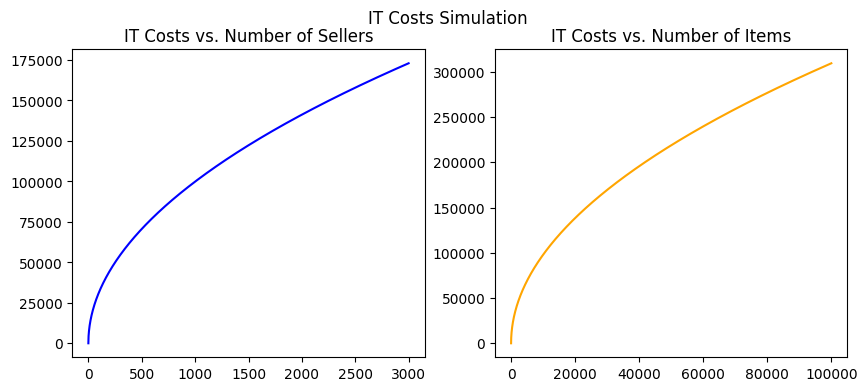

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

alpha = 3157.27
beta = 978.23

x_sellers = np.arange(3_000)
y_it_costs_sellers = alpha * x_sellers ** 0.5

x_items = np.arange(100_000)
y_it_costs_items = beta * x_items ** 0.5

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x_sellers, y_it_costs_sellers, label='IT costs per seller', color='blue')
plt.title('IT Costs vs. Number of Sellers')
plt.subplot(1, 2, 2)
plt.plot(x_items, y_it_costs_items, label='IT costs per item', color='orange')
plt.title('IT Costs vs. Number of Items')
plt.suptitle('IT Costs Simulation');

### Key Findings, so far

- `wait_time`, düşük review_score’ların arkasındaki en önemli faktördür.  
- `wait_time`, seller’ın `delay_to_carrier` süresi + `carrier_delivery_time` toplamından oluşur.  
- Carrier’ın delivery time’ı Olist’in doğrudan kontrolünde olmadığı için, bunu iyileştirmek hızlı kazanım sağlayacak bir öneri değildir.  
- Buna karşılık, daha iyi bir `seller` seçimi `delay_to_carrier` değerini olumlu şekilde etkileyebilir ve Olist üzerindeki kötü `review_scores` sayısını azaltabilir.  
- Kötü review’lardaki yorumlar, bazılarının seller’dan veya bizzat üründen kaynaklandığını göstermiştir.

💡 Aşağıdaki bölüm 2’deki guided seller analysis ile başlamanızı öneririz.

💪 Ancak bölüm 3 ile başka hipotezleri araştırmakta özgürsünüz.

## 2. Olist, performansları düşük satıcıları pazarından çıkarmalı mı? 🕵🏻
*(önerilen)*

Olist’in marketplace’inden en kötü seller’ları çıkarmanın etkisini analiz etmek için bir **what-if analysis** yapacağız.

👉 **Olist bu seller’ları en baştan hiç kabul etmemiş olsaydı ne olurdu?**  

*(Gerçekte, kimin iyi seller olduğunu önceden bilmek zordur, ancak bu yaklaşımla başlayıp daha sonra iterasyon yapacağız.)*


### 2.1 Veri Hazırlama

Her bir `seller_id` için, başlangıçtan itibaren kümülatif olarak hesaplayın:
- seller’ın getirdiği `revenues`
- seller’ın kötü review’larına bağlı `review_costs`
- ortaya çıkan `profits` (revenues - costs)

👉 İhtiyacınız olan DataFrame’i oluşturmak için adım adım bir strateji yazın.

⚠️ **Sıfırdan başlamayın, mevcut package’ınızı güncelleyin!** 😉

**Çözüm, notebook’a yeni kod yazmakta değil — `.py` dosyalarınızdaki kodu değiştirmektedir.**

`olist` package’ınız içindeki `Seller` class’ından başlayarak:

`get_training_data` method’unu düzenleyin; döndürdüğü DataFrame şu alanları içermeli:
- `revenues`: subscription + sales fees toplamı  
- `cost_of_reviews`: kötü review’lara bağlı toplam cost  
- `profits`: `revenues` - `cost_of_reviews`

`cost_of_reviews` için önce başka bir method’u değiştirmeniz gerekecek. Bununla ilgili olan method hangisi?

### 2.2 IT Maliyetleri Hariç Varsayım Analizi

👉 Gerçek analizi yapma zamanı. İlk olarak bunu IT costs **dahil etmeden** gerçekleştireceğiz.

Adımlarımız:  

1️⃣ Sellers verisini load edin ve profits değerine göre azalan şekilde sıralayın.

2️⃣ Cumulative değerleri hesaplayın:
   - Her satır için cumulative revenues hesaplayın.
   - Her satır için cumulative profits hesaplayın.
   - Her satır için cumulative items sold hesaplayın.

   Pandas ile cumulative sum nasıl hesaplanır, araştırın.

3️⃣ Sonuçlarınızı plot edin ve analiz edin. Pandas’ın `.plot()` method’unu kullanın.

4️⃣ Profits’e göre tutulması gereken optimum seller sayısını belirleyin. (İpucu: `np.argmax` araştırın). Bu kararın etkisi ne olurdu:
   - Net profit (IT costs dahil etmediğimiz için IT costs öncesi)?
   - Total revenues?
   - Seller sayısı?
   - Satılan item sayısı?

In [3]:
import pandas as pd
pd.set_option("future.infer_string", False)

from olist.seller_updated import Seller
sellers = Seller().get_training_data()
print(sellers.columns.tolist())
sellers.head()
from olist.seller_updated import Seller
sellers = Seller().get_training_data()
print(sellers.columns.tolist())
sellers.head()

['seller_id', 'seller_city', 'seller_state', 'delay_to_carrier', 'wait_time', 'date_first_sale', 'date_last_sale', 'months_on_olist', 'share_of_five_stars', 'share_of_one_stars', 'review_score', 'cost_of_reviews', 'n_orders', 'quantity', 'quantity_per_order', 'sales', 'revenues', 'profits']
['seller_id', 'seller_city', 'seller_state', 'delay_to_carrier', 'wait_time', 'date_first_sale', 'date_last_sale', 'months_on_olist', 'share_of_five_stars', 'share_of_one_stars', 'review_score', 'cost_of_reviews', 'n_orders', 'quantity', 'quantity_per_order', 'sales', 'revenues', 'profits']


,seller_id,seller_city,seller_state,delay_to_carrier,wait_time,date_first_sale,date_last_sale,months_on_olist,share_of_five_stars,share_of_one_stars,review_score,cost_of_reviews,n_orders,quantity,quantity_per_order,sales,revenues,profits
0,3442f8959a84dea7ee197c632cb2df15,campinas,SP,0.000000,13.018588,2017-05-05 16:25:11,2017-08-30 12:50:19,4.0,0.333333,0.333333,3.000000,140,3,3,1.000,218.70,341.870,201.870
1,d1b65fc7debc3361ea86b5f14c68d2e2,mogi guacu,SP,0.000000,9.065716,2017-03-29 02:10:34,2018-06-06 20:15:21,14.0,0.731707,0.048780,4.560976,240,40,41,1.025,11703.07,2290.307,2050.307
2,ce3ad9de960102d0677a81f5d0bb7b2d,rio de janeiro,RJ,0.000000,4.042292,2018-07-30 12:44:49,2018-07-30 12:44:49,0.0,1.000000,0.000000,5.000000,0,1,1,1.000,158.00,15.800,15.800
3,c0f3eea2e14555b6faeea3dd58c1b1c3,sao paulo,SP,0.000000,5.667187,2018-08-03 00:44:08,2018-08-03 00:44:08,0.0,1.000000,0.000000,5.000000,0,1,1,1.000,79.99,7.999,7.999
4,51a04a8a6bdcb23deccc82b0b80742cf,braganca paulista,SP,3.353727,35.314861,2017-11-14 12:15:25,2017-11-14 12:15:25,0.0,0.000000,1.000000,1.000000,100,1,1,1.000,167.99,16.799,-83.201


### 2.3 IT maliyetleri ile varsayımsal analiz (İsteğe bağlı)

👉 Bu kez IT costs dahil edilerek gerçek analizi yapma zamanı.

Adımlarımız şunlar:  

1️⃣ İki parametreye göre IT costs hesaplayan bir function yazın: seller sayısı ve item sayısı. Temelde matematiksel formülü Python kullanarak yazmanız yeterli.

2️⃣ Sellers verisini load edin ve (IT costs öncesi) kârlarına göre azalan şekilde sıralayın.

3️⃣ Cumulative değerleri hesaplayın (önceki kodu yeniden kullanın):
   - Her satır için cumulative revenues hesaplayın.
   - Her satır için cumulative profits hesaplayın.
   - Her satır için toplam satılan item miktarının cumulative değerini hesaplayın.  

4️⃣ IT costs etkisini hesaplayın:
   - 1️⃣. adımda yazdığınız function’ı kullanarak her satır için cumulative IT cost ekleyin.
   - IT costs sonrası net profit’i hesaplayın.

5️⃣ Sonuçlarınızı plot edin ve analiz edin.

6️⃣ Bu kez IT costs sonrası kârları baz alarak tutulması gereken optimum seller sayısını belirleyin. Bu kararın etkisi ne olurdu:
   - IT costs sonrası net profit?
   - IT costs öncesi net profit?
   - IT costs?
   - Total revenues?
   - Seller sayısı?
   - Satılan item sayısı?

Analizinizde IT costs ne kadar önemliydi?


IT costs sonrası net profit: 976.026,08
IT costs öncesi net profit: 1.351.939,83
IT costs: 375.913,75
Total revenues: 2.147.749,83
Seller sayısı: 2021
Satılan item sayısı: 57.209

"Analizinizde IT costs ne kadar önemliydi?" sorusuna cevap:

IT costs, kararı önemli ölçüde değiştirdi. IT costs'u hesaba katmadan bakıldığında, Olist'in 2483 seller'a kadar tutması kârlı görünüyordu ve bu noktada net kâr ~1,35M idi. Ancak IT costs eklendiğinde:

Optimum seller sayısı 462 seller daha az (%18,6 azalma) çıkıyor — yani en az kârlı ~462 seller'ın tutulması, kazandırdıkları gelirden daha fazla altyapı maliyetine yol açıyor.
Toplam net kâr 375.913,75 (%27,8) daha düşük çıkıyor — bu da IT maliyetlerinin toplam kâr üzerinde ihmal edilemez bir etkisi olduğunu gösteriyor.
Grafikteki eğri şekli de bunu doğruluyor: turuncu çizgi (IT costs sonrası), sağ tarafta belirgin şekilde daha keskin bir düşüş gösteriyor — çünkü IT costs, √n_sellers ile arttığı için marjinal seller sayısı yükseldikçe maliyet de hızlanarak büyüyor, ama gelir katkısı azalan sellerlar için giderek küçülüyor.

Kısacası: sadece revenue/profit'e bakmak, gerçekte kârsız olan ~460 seller'ı yanlışlıkla "tutulmalı" diye işaretliyordu. IT costs'u modele dahil etmek, kararı gerçek operasyonel maliyetlerle hizalayarak daha doğru (ve daha muhafazakar) bir optimum noktaya taşıyor. Bu, gerçek dünya iş kararlarında "görünür" maliyetlerin yanında "görünmez"/altyapısal maliyetleri de hesaba katmanın neden kritik olduğunu gösteren güzel bir örnek.

In [4]:
import numpy as np

def get_it_costs(n_sellers, n_items, alpha=3157.27, beta=978.23):
    """
    IT_costs = alpha * sqrt(n_sellers) + beta * sqrt(n_items)
    """
    return alpha * np.sqrt(n_sellers) + beta * np.sqrt(n_items)

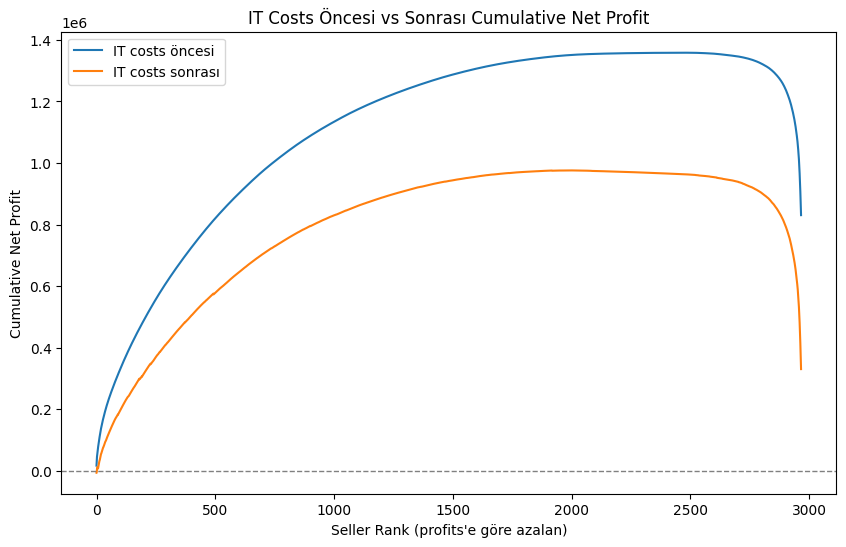

[IT costs sonrası] Optimum seller sayısı: 2021
IT costs sonrası net profit: 976026.08
IT costs öncesi net profit: 1351939.83
IT costs: 375913.75
Total revenues: 2147749.83
Seller sayısı: 2021
Satılan item sayısı: 57209.00

[IT costs öncesi] Optimum seller sayısı: 2483


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 2) Sellers verisini load et ve (IT costs öncesi) profits'e göre azalan sırala
sellers = Seller().get_training_data()
sellers = sellers.sort_values(by="profits", ascending=False).reset_index(drop=True)

# 3) Cumulative değerleri hesapla (önceki koddan)
sellers["cumulative_revenues"] = sellers["revenues"].cumsum()
sellers["cumulative_profits"] = sellers["profits"].cumsum()
sellers["cumulative_quantity"] = sellers["quantity"].cumsum()

# Seller sayacı (kaçıncı sırada, 1'den başlayarak)
sellers["n_sellers"] = range(1, len(sellers) + 1)

# 4) IT costs etkisini hesapla
# Her satır için: o ana kadar tutulan seller sayısı ve satılan item sayısı ile IT cost
sellers["cumulative_it_costs"] = get_it_costs(
    n_sellers=sellers["n_sellers"],
    n_items=sellers["cumulative_quantity"]
)

# IT costs sonrası net profit
sellers["cumulative_profits_after_it"] = (
    sellers["cumulative_profits"] - sellers["cumulative_it_costs"]
)

sellers.head()

# 5) Plot ile analiz et
sellers[["cumulative_profits", "cumulative_profits_after_it"]].plot(
    title="IT Costs Öncesi vs Sonrası Cumulative Net Profit",
    xlabel="Seller Rank (profits'e göre azalan)",
    ylabel="Cumulative Net Profit",
    figsize=(10, 6)
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.legend(["IT costs öncesi", "IT costs sonrası"])
plt.show()

# 6) IT costs sonrası kârları baz alarak optimum seller sayısını belirle
optimal_index_after_it = np.argmax(sellers["cumulative_profits_after_it"])
optimal_row_after_it = sellers.iloc[optimal_index_after_it]

print(f"[IT costs sonrası] Optimum seller sayısı: {optimal_index_after_it + 1}")
print(f"IT costs sonrası net profit: {optimal_row_after_it['cumulative_profits_after_it']:.2f}")
print(f"IT costs öncesi net profit: {optimal_row_after_it['cumulative_profits']:.2f}")
print(f"IT costs: {optimal_row_after_it['cumulative_it_costs']:.2f}")
print(f"Total revenues: {optimal_row_after_it['cumulative_revenues']:.2f}")
print(f"Seller sayısı: {optimal_row_after_it['n_sellers']}")
print(f"Satılan item sayısı: {optimal_row_after_it['cumulative_quantity']:.2f}")

# Karşılaştırma için: IT costs öncesi optimum nokta neydi?
optimal_index_before_it = np.argmax(sellers["cumulative_profits"])
print(f"\n[IT costs öncesi] Optimum seller sayısı: {optimal_index_before_it + 1}")

## 3. Diğer Yaklaşımları Araştırın 🕵️
*(isteğe bağlı)*

- Olist, en kötü performans gösteren ürünleri/kategorileri pazarından tamamen kaldırmalı mı?
- Olist, birkaç aylık balayı döneminden sonra, sadece sürekli olarak düşük performans gösteren satıcıları kaldırmalı mı?
- Olist, satıcılardan ürün listelerine belirli bilgileri eklemelerini zorunlu kılmalı mı?
- Olist, günün belirli saatlerinde müşterilerden satın alma onayı istemeli mi?
- Olist, gecikmeleri önlemek için belirli eyaletler arasındaki satıcı/müşteri çiftlerini kısıtlamalı mı?
- Olist, bazı maliyet varsayımları önerilerek yeni satıcılar kazanmalı mı?
- ...

## Sıra Sende!

🧺 Bu defteri düzenli tutun! 

🗣 📊 Bu `Communicate`  ünitesinin sonunda, en sevdiğiniz TA'ya görüşlerinizi sunacaksınız 💪

1) Olist, en kötü performans gösteren ürünleri/kategorileri pazarından tamamen kaldırmalı mı?

Kısmen evet, ama tamamen değil. Analizimizdeki mantık aynen buraya uyarlanabilir: eğer bir ürün kategorisi için cumulative profit hesaplasak, muhtemelen benzer bir eğri görürüz — bazı kategoriler net negatif katkı yapıyor olabilir (yüksek iade oranı, düşük review score, yüksek lojistik maliyeti). Ancak "en kötü performans" tek boyutlu değerlendirilmemeli: düşük kârlı bir kategori, müşteri trafiği çekiyor olabilir (loss leader etkisi) ya da yeni büyüme potansiyeli taşıyabilir. Doğru yaklaşım: bizim yaptığımız gibi kategori bazında cumulative profit/IT cost analizi yapıp, gerçekten net negatif olan kategorileri kaldırmak — sadece "en kötü" etiketine değil, sayılara bakmak.

2) Olist, balayı döneminden sonra sürekli düşük performans gösteren satıcıları kaldırmalı mı?

Evet, ve bu bizim analizimizin doğal bir uzantısı. Yeni sellerlara bir "ısınma dönemi" tanımak mantıklı (review score'ları ve satış hacimleri henüz oturmamış olabilir), ama "sürekli" düşük performans gösterenler için optimum seller sayısı analizimiz zaten bunu gösteriyor: en düşük profitli ~462 seller'ı tutmak IT maliyetleriyle birlikte net kayıp yaratıyor. Yani bu soru aslında bizim bulgumuzun operasyonel karşılığı — "kimi kaldırmalı" sorusunun cevabı, cumulative_profits_after_it eğrisinin tepe noktasından sonraki sellerlar.

3) Olist, satıcılardan ürün listelerine belirli bilgileri eklemelerini zorunlu kılmalı mı?

Muhtemelen evet, düşük maliyetli/yüksek etkili bir müdahale olabilir. Review cost formülümüzde (1 yıldız = 100 BRL, 2 yıldız = 50 BRL gibi) kötü review'ların doğrudan maliyet olarak modellendiğini gördük. Eksik/yanıltıcı ürün bilgisi, muhtemelen düşük review score'ların önemli bir nedeni (müşteri beklentisi ile gerçek ürün uyuşmuyor). Zorunlu alanlar (boyut, malzeme, gerçek fotoğraf sayısı vb.) eklemek, review cost'unu düşürerek profit'i artırabilir — ama bunu test etmek için bizim yapmadığımız ek bir analiz gerekir: "eksik bilgili ürünlerin review score'u, tam bilgili ürünlere göre nasıl?"

4) Olist, günün belirli saatlerinde müşterilerden satın alma onayı istemeli mi?

Bu, wait_time/delay_to_carrier metriklerimizle dolaylı ilişkili ama zayıf bir öneri. Satın alma onayı istemek, dönüşüm oranını düşürme riski taşır (ekstra sürtünme = terk edilen sepetler) ve bizim elimizdeki veri bunun teslimat gecikmesini azaltacağına dair doğrudan bir kanıt sunmuyor. Muhtemelen daha zayıf bir çözüm — gecikme sorunu (delay_to_carrier) daha çok seller'ın kargoya verme sürecinde, müşteri tarafında değil.

5) Olist, gecikmeleri önlemek için belirli eyaletler arası satıcı/müşteri çiftlerini kısıtlamalı mı?

Bu, get_seller_delay_wait_time ve get_distance_seller_customer fonksiyonlarımızla doğrudan test edilebilir bir hipotez. Eğer belirli eyalet çiftlerinde delay_to_carrier veya wait_time sistematik olarak yüksekse (mesafeye bağlı olmayan, yapısal bir gecikme), o çiftleri kısıtlamak mantıklı olur. Ama coğrafi olarak büyük bir ülkede (Brezilya) bunu tamamen kısıtlamak, o bölgelerdeki müşterilere hizmet vermemek anlamına gelir — muhtemelen daha iyi çözüm, o rotalar için lojistik ortaklığı iyileştirmek ya da fiyatlandırmayı (kargo ücretini) gecikme riskini yansıtacak şekilde ayarlamak.

6) Olist, bazı maliyet varsayımları önererek yeni satıcılar kazanmalı mı?

Bizim IT costs analizimiz burada doğrudan uygulanabilir: eğer yeni bir seller'ın beklenen n_items satışı, β√n_items maliyetini revenues'in üzerine çıkarmayacaksa (yani marjinal katkısı pozitifse), o seller'ı kazanmak mantıklı. Yani "hangi profildeki yeni satıcıları hedeflemeli" sorusuna cevap: yüksek hacimli, düşük review-riskli kategorilerde satış yapması beklenen sellerlar — çünkü hem revenues'i artırıyorlar hem de cost_of_reviews'i düşük tutuyorlar.